CREDIT CARD FRAUD DETECTION

In [25]:
import kagglehub, os
path = kagglehub.dataset_download('mlg-ulb/creditcardfraud')
print(path)
print(os.listdir(path))

Using Colab cache for faster access to the 'creditcardfraud' dataset.
/kaggle/input/creditcardfraud
['creditcard.csv']


In [26]:
import pandas as pd
from sklearn.model_selection import train_test_split


In [27]:
import pandas as pd
DATA_PATH = os.path.join(path, 'creditcard.csv')
df = pd.read_csv(DATA_PATH)
print(df.shape)

(284807, 31)


In [28]:
print(df["Class"].nunique())
print(df["Class"].value_counts())

2
Class
0    284315
1       492
Name: count, dtype: int64


In [29]:
print(df.describe())

                Time            V1            V2            V3            V4  \
count  284807.000000  2.848070e+05  2.848070e+05  2.848070e+05  2.848070e+05   
mean    94813.859575  1.175161e-15  3.384974e-16 -1.379537e-15  2.094852e-15   
std     47488.145955  1.958696e+00  1.651309e+00  1.516255e+00  1.415869e+00   
min         0.000000 -5.640751e+01 -7.271573e+01 -4.832559e+01 -5.683171e+00   
25%     54201.500000 -9.203734e-01 -5.985499e-01 -8.903648e-01 -8.486401e-01   
50%     84692.000000  1.810880e-02  6.548556e-02  1.798463e-01 -1.984653e-02   
75%    139320.500000  1.315642e+00  8.037239e-01  1.027196e+00  7.433413e-01   
max    172792.000000  2.454930e+00  2.205773e+01  9.382558e+00  1.687534e+01   

                 V5            V6            V7            V8            V9  \
count  2.848070e+05  2.848070e+05  2.848070e+05  2.848070e+05  2.848070e+05   
mean   1.021879e-15  1.494498e-15 -5.620335e-16  1.149614e-16 -2.414189e-15   
std    1.380247e+00  1.332271e+00  1.23709

In [30]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [31]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['Class'])          # everything except the target
y = df["Class"]                         # only the target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,                  # 80/20 split
    random_state=42,
    stratify=y
)

In [32]:
print(len(X_train))
print(len(X_test))

227845
56962


In [33]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
cols = ["Time", "Amount"]

X_train[cols] = scaler.fit_transform(X_train[cols])   # learns AND applies, in one call
X_test[cols]  = scaler.transform(X_test[cols])    # applies only

In [34]:
X_train[cols].describe()

,Time,Amount
count,2.278450e+05,2.278450e+05
mean,-1.409578e-16,3.742243e-17
std,1.000002e+00,1.000002e+00
min,-1.998073e+00,-3.516894e-01
25%,-8.561495e-01,-3.291944e-01
50%,-2.122647e-01,-2.639429e-01
75%,9.366285e-01,-4.262209e-02
max,1.640549e+00,1.021170e+02


In [35]:
print(df["Class"].sum())          # 492
print(df["Class"].mean() * 100)   # fraud percentage, about 0.17

492
0.1727485630620034


In [36]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)          # train
y_pred = model.predict(X_test)           # predict 0/1 on the test set

print(accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

0.9991573329588147
[[56851    13]
 [   35    63]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.83      0.64      0.72        98

    accuracy                           1.00     56962
   macro avg       0.91      0.82      0.86     56962
weighted avg       1.00      1.00      1.00     56962



Here the precison was high - so the targetting customers was low but the fraud transactions was high.

In [37]:
model_bal = LogisticRegression(max_iter = 1000, class_weight = "balanced")
model_bal.fit(X_train, y_train)
y_pred_bal = model_bal.predict(X_test)

print(accuracy_score(y_test, y_pred_bal))
print(confusion_matrix(y_test, y_pred_bal))
print(classification_report(y_test, y_pred_bal))

0.9755275446789088
[[55478  1386]
 [    8    90]]
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56864
           1       0.06      0.92      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.98      0.99     56962



Data has been balanced
Recall increased - so the money loss will be decreased but targetting the genuine customers as fraud increased.

In [38]:
!pip install imbalanced-learn

In [39]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

In [40]:
print(y_train_sm.value_counts())
print(y_train.value_counts())

Class
0    227451
1    227451
Name: count, dtype: int64
Class
0    227451
1       394
Name: count, dtype: int64


In [41]:
model_sm = LogisticRegression(max_iter = 1000)
model_sm.fit(X_train_sm, y_train_sm)
y_pred_bal = model_sm.predict(X_test)

print(accuracy_score(y_test, y_pred_bal))
print(confusion_matrix(y_test, y_pred_bal))
print(classification_report(y_test, y_pred_bal))

0.9742108774270566
[[55403  1461]
 [    8    90]]
              precision    recall  f1-score   support

           0       1.00      0.97      0.99     56864
           1       0.06      0.92      0.11        98

    accuracy                           0.97     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.97      0.99     56962



Smote risk is overfitting

In [42]:
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=42, stratify=y_train)
model_val = LogisticRegression(max_iter = 1000, class_weight = "balanced")
model_val.fit(X_tr, y_tr)
val_probs = model_val.predict_proba(X_val)[:, 1]

In [43]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score
for t in [0.5, 0.7, 0.9, 0.95, 0.99, 0.995, 0.999]:
    preds = (val_probs >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, preds).ravel()
    prec = precision_score(y_val, preds)
    rec  = recall_score(y_val, preds)
    print(t, tp, fp, fn, round(prec, 2), round(rec, 2))

0.5 89 1413 10 0.06 0.9
0.7 86 696 13 0.11 0.87
0.9 81 304 18 0.21 0.82
0.95 80 204 19 0.28 0.81
0.99 79 62 20 0.56 0.8
0.995 77 47 22 0.62 0.78
0.999 76 29 23 0.72 0.77


In [44]:
test_probs = model_val.predict_proba(X_test)[:, 1]
test_preds = (test_probs >= 0.99).astype(int)
print(confusion_matrix(y_test, test_preds))
print(classification_report(y_test, test_preds))

[[56797    67]
 [   14    84]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.56      0.86      0.67        98

    accuracy                           1.00     56962
   macro avg       0.78      0.93      0.84     56962
weighted avg       1.00      1.00      1.00     56962



In [45]:
from sklearn.metrics import average_precision_score
base_probs = model.predict_proba(X_test)[:, 1]

In [46]:
print(average_precision_score(y_test, base_probs))
print(average_precision_score(y_test, test_probs))

0.7431691767832423
0.7193006571960017


In [47]:
bal_probs = model_bal.predict_proba(X_test)[:, 1]
print(average_precision_score(y_test, bal_probs))
print(average_precision_score(y_test, test_probs))

0.7159122424484009
0.7193006571960017


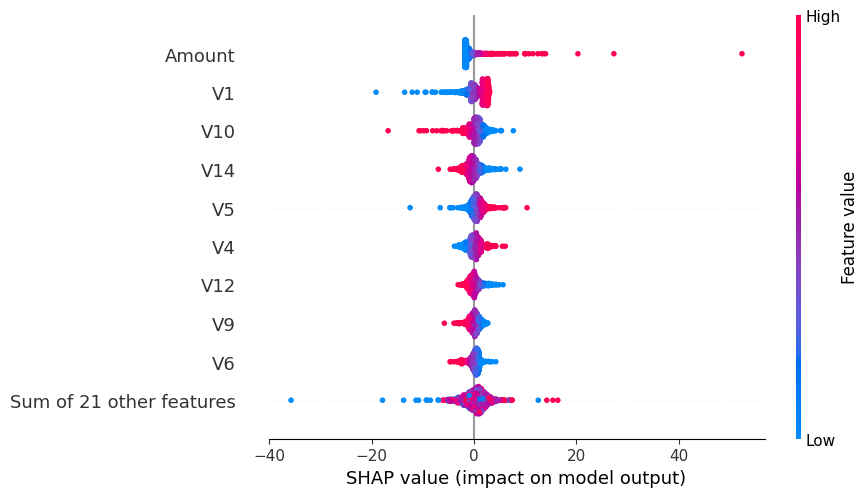

In [48]:
!pip install shap
import shap

explainer = shap.LinearExplainer(model_val, X_tr)
shap_values = explainer(X_test[:1000])

shap.plots.beeswarm(shap_values)

In [49]:
print(df[df["Class"] == 1]["Amount"].mean())

122.21132113821139


In [50]:
print(df[df["Class"] == 0]["Amount"].mean())

88.29102242231328


In [51]:
print(df[df["Class"] == 1]["Amount"].median())
print(df[df["Class"] == 0]["Amount"].median())

9.25
22.0
